# Vision — OCR → Klasifikasi Dokumen (EasyOCR + TF-IDF)
**Kapan dipakai:** gambar dokumen (struk, surat, kwitansi) harus dikelompokkan menurut jenisnya
dan isi tulisannya membedakan jenis.

**Langkah:** gambar dibaca jadi teks (EasyOCR) → teks diklasifikasi seperti notebook teks
biasa (TF-IDF + model linear).

**Data demo:** 200 gambar dokumen SINTETIS, 4 jenis (`struk`, `surat_resmi`, `undangan`,
`kwitansi`). Alternatif tanpa OCR (tampilan dokumen saja): `vision/klasifikasi_embedding`.

In [1]:
import easyocr
import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/vision/ocr"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/dokumen_train.csv"
TEST_CSV = f"{DATA_FOLDER}/dokumen_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/dokumen_test_labels.csv"   # hanya ada di data latihan
EASYOCR_FOLDER = "../../../pretrained/easyocr"

LANGUAGES = ["en", "id"]
PATH_COL = "path"     # path gambar, relatif terhadap DATA_FOLDER
TARGET = "jenis"
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts())
train.head()

train: (150, 3) | test: (50, 2)
jenis
undangan       41
struk          37
surat_resmi    37
kwitansi       35
Name: count, dtype: int64


,id,path,jenis
0,0,dokumen/dok095.png,kwitansi
1,1,dokumen/dok015.png,kwitansi
2,2,dokumen/dok030.png,undangan
3,3,dokumen/dok158.png,undangan
4,4,dokumen/dok128.png,struk


## OCR semua gambar → kolom `teks`

In [4]:
reader = easyocr.Reader(LANGUAGES, gpu=torch.cuda.is_available(),
                        model_storage_directory=EASYOCR_FOLDER,
                        user_network_directory=EASYOCR_FOLDER,
                        download_enabled=False, verbose=False)


def read_text(path):
    pieces = reader.readtext(f"{DATA_FOLDER}/{path}", detail=0)   # daftar potongan teks
    return " ".join(pieces)


print(read_text(train.loc[0, PATH_COL])[:200])

train["teks"] = train[PATH_COL].apply(read_text)
test["teks"] = test[PATH_COL].apply(read_text)
train.to_csv("train_ocr.csv", index=False)
train[["teks", TARGET]].head()

KWITANSI No. 3497 Telah terima dari: Budi Santoso sejumlah: Rp4.750.0oo Untuk pembayaran: sewa Tanggal 9 Januari 2025 Penerima, tanda tangan Uang


,teks,jenis
0,KWITANSI No. 3497 Telah terima dari: Budi Sant...,kwitansi
1,KWITANSI No. 6329 Telah terima dari: Dewi Lest...,kwitansi
2,UNDANGAN Kepada Yth. Budi Santoso Kami mengund...,undangan
3,UNDANGAN Kepada Ych. Andi Nijaya Kamı mengunda...,undangan
4,WARUNG BU SITI JI. Sudirman No.78 Tanggal: 18-...,struk


## EDA: panjang teks per jenis

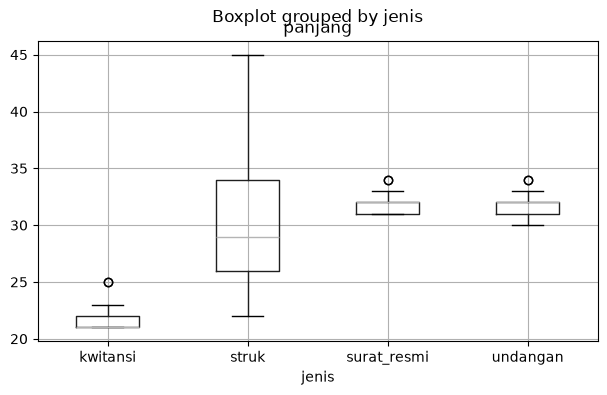

In [5]:
train["panjang"] = train["teks"].str.split().str.len()
train.boxplot(column="panjang", by=TARGET, figsize=(7, 4))
plt.show()

## Split train / validasi

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    train["teks"], train[TARGET], test_size=0.25, stratify=train[TARGET], random_state=SEED
)

## Model
`char_wb` (potongan huruf) lebih tahan salah baca OCR daripada kata utuh.
Pilih SATU vectorizer dan SATU model: hapus `#` di baris yang ingin dipakai.

In [7]:
vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)
# vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

model = LogisticRegression(C=10, max_iter=2000)
# model = LinearSVC(C=1.0)
# model = MultinomialNB(alpha=0.1)

pipe = make_pipeline(vectorizer, model)
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['kwitansi','struk','surat_resmi','undangan']"
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'char_wb'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(2, ...)"
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


## Evaluasi di validasi

F1 macro: 1.0
              precision    recall  f1-score   support

    kwitansi       1.00      1.00      1.00         9
       struk       1.00      1.00      1.00         9
 surat_resmi       1.00      1.00      1.00         9
    undangan       1.00      1.00      1.00        11

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38



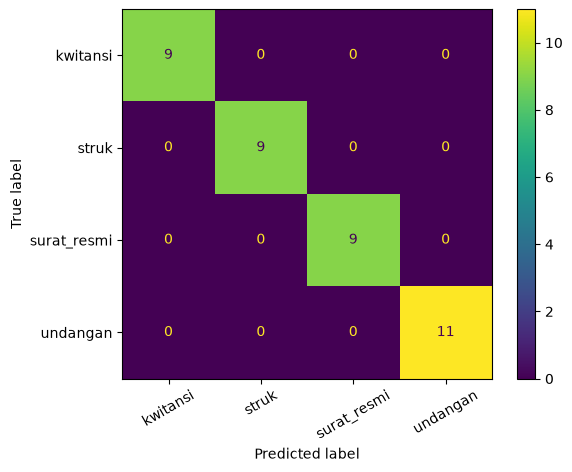

In [8]:
val_predictions = pipe.predict(X_val)
print("F1 macro:", round(f1_score(y_val, val_predictions, average="macro"), 4))
print(classification_report(y_val, val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, xticks_rotation=30)
plt.show()

## Latih ulang di semua data + submission

In [9]:
pipe.fit(train["teks"], train[TARGET])
predictions = pipe.predict(test["teks"])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["jenis"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,jenis
0,150,struk
1,151,surat_resmi
2,152,surat_resmi
3,153,struk
4,154,surat_resmi


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)["jenis"]
print("F1 macro test (kunci latihan):", round(f1_score(test_key, predictions, average="macro"), 4))

F1 macro test (kunci latihan): 1.0
